     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 11.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.1 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incompat

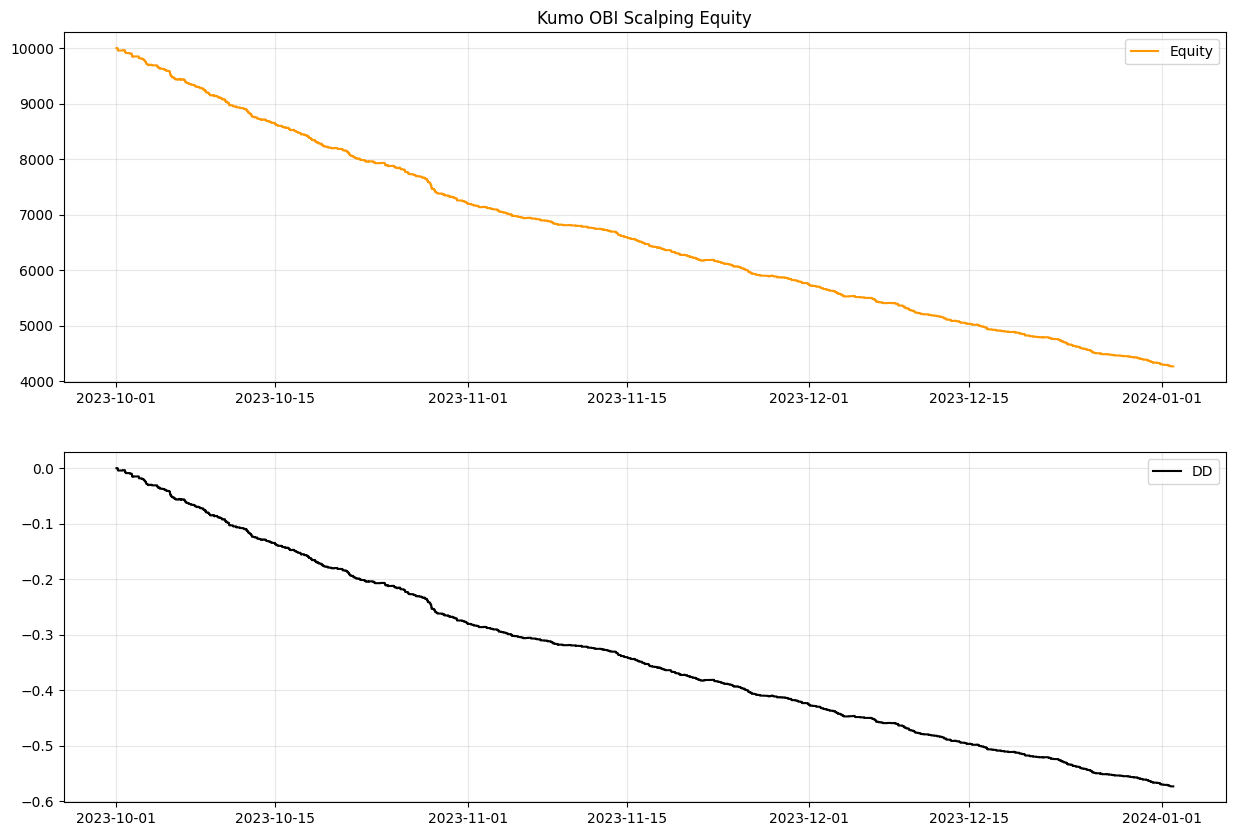

In [1]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC: KUMO BREAKOUT + OBI SCALPING
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1m',        # KHUNG M1 (SCALPING)
    # Lưu ý: 1m rất nặng, test 3-6 tháng gần nhất để tránh lag Colab
    'START_DATE': '01/10/2023',
    'END_DATE': '01/01/2024',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators ---
    'ICHIMOKU_TENKAN': 9,
    'ICHIMOKU_KIJUN': 26,
    'ICHIMOKU_SPAN_B': 52,
    'ICHIMOKU_DISPLACE': 26,

    'RSI_PERIOD': 14,
    'RSI_BUY_THRES': 55,
    'RSI_SELL_THRES': 45,

    # --- OBI Proxy Settings (Volume Spread Analysis) ---
    'OBI_VOL_FACTOR': 1.5,   # Volume phải lớn gấp 1.5 lần trung bình
    'OBI_BODY_FACTOR': 0.6,  # Thân nến chiếm > 60% tổng chiều dài

    # --- Management ---
    'SL_PIPS_BUFFER': 20.0,  # Buffer an toàn (USD trên BTC)
    'MAX_RISK_PCT': 0.001,   # 0.1% Equity Stop (Cắt lỗ cứng theo % giá)

    'RR_RATIO': 1.5,         # Risk:Reward 1:1.5
    'TIME_EXIT_CANDLES': 5,  # Thoát sau 5 nến nếu không chạy

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0001       # M1 trượt giá sẽ cao hơn H1
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU (OPTIMIZED)
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    # Check IP
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval}) from {base_url}...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            # In ít hơn vì M1 rất nhiều nến
            if len(all_klines) % 10000 == 0:
                print(f"   -> Downloaded: {len(all_klines)} candles")
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    print(f"✅ Total: {len(df)} candles.")
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Kumo Breakout + Simulated OBI)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating Indicators & Running Scalping Strategy...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. Ichimoku Cloud (Manual Calculation for Precision)
    # Tenkan (9)
    high_9 = df['High'].rolling(c['ICHIMOKU_TENKAN']).max()
    low_9 = df['Low'].rolling(c['ICHIMOKU_TENKAN']).min()
    tenkan = (high_9 + low_9) / 2

    # Kijun (26)
    high_26 = df['High'].rolling(c['ICHIMOKU_KIJUN']).max()
    low_26 = df['Low'].rolling(c['ICHIMOKU_KIJUN']).min()
    kijun = (high_26 + low_26) / 2

    # Span A & B (Shifted Forward 26)
    # Để biết giá trị mây tại thời điểm hiện tại t, ta cần giá trị đã được tính tại t-26
    df['SpanA'] = ((tenkan + kijun) / 2).shift(c['ICHIMOKU_DISPLACE'])

    high_52 = df['High'].rolling(c['ICHIMOKU_SPAN_B']).max()
    low_52 = df['Low'].rolling(c['ICHIMOKU_SPAN_B']).min()
    df['SpanB'] = ((high_52 + low_52) / 2).shift(c['ICHIMOKU_DISPLACE'])

    # Xác định biên mây
    df['Kumo_Top'] = df[['SpanA', 'SpanB']].max(axis=1)
    df['Kumo_Bottom'] = df[['SpanA', 'SpanB']].min(axis=1)

    # 2. RSI
    df['RSI'] = ta.rsi(df['Close'], length=c['RSI_PERIOD'])

    # 3. OBI PROXY (Volume + Price Action)
    # Giả lập: OBI Buy khi nến xanh mạnh + Vol lớn. OBI Sell khi nến đỏ mạnh + Vol lớn.
    df['Vol_MA'] = ta.sma(df['Volume'], length=20)

    # Body Size vs Candle Range
    candle_range = df['High'] - df['Low']
    body_size = (df['Close'] - df['Open']).abs()

    # Điều kiện Vol > 1.5 * Vol trung bình
    vol_spike = df['Volume'] > (df['Vol_MA'] * c['OBI_VOL_FACTOR'])
    # Điều kiện thân nến dài
    strong_body = body_size > (candle_range * c['OBI_BODY_FACTOR'])

    df['OBI_Buy'] = (df['Close'] > df['Open']) & vol_spike & strong_body
    df['OBI_Sell'] = (df['Close'] < df['Open']) & vol_spike & strong_body

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    kumo_top = df['Kumo_Top'].values; kumo_bottom = df['Kumo_Bottom'].values
    rsi = df['RSI'].values
    obi_buy = df['OBI_Buy'].values; obi_sell = df['OBI_Sell'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. EXIT LOGIC
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            bars_held = i - entry_idx

            if position == 1:
                # Dynamic Counter-OBI Exit (Nếu xuất hiện OBI Sell mạnh ngược lại -> Thoát)
                if obi_sell[i]:
                    exit_signal = True; exit_reason = "Counter OBI"; raw_exit_price = closes[i]
                # SL / TP / Time
                elif lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif bars_held >= c['TIME_EXIT_CANDLES']:
                    # Time stop: Nếu chưa lãi thì cắt
                    if closes[i] <= entry_price:
                         exit_signal = True; exit_reason = "Time Stop"; raw_exit_price = closes[i]
                    # Nếu đang lãi nhẹ thì giữ thêm (tùy chỉnh), ở đây ta cắt luôn theo luật 5 nến
                    else:
                         exit_signal = True; exit_reason = "Time Stop"; raw_exit_price = closes[i]

            elif position == -1:
                if obi_buy[i]:
                    exit_signal = True; exit_reason = "Counter OBI"; raw_exit_price = closes[i]
                elif highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif bars_held >= c['TIME_EXIT_CANDLES']:
                     exit_signal = True; exit_reason = "Time Stop"; raw_exit_price = closes[i]

            if exit_signal:
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)
                trades.append({'Date': times[i], 'Type': 'Long' if position == 1 else 'Short', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0

        # 2. ENTRY LOGIC
        if position == 0:
            # --- BUY SETUP ---
            # 1. Previous High < Kumo High (Nến trước nằm dưới hoặc trong mây)
            was_below_cloud = highs[i-1] < kumo_top[i-1]
            # 2. Current Close > Kumo High (Phá vỡ lên)
            break_cloud = closes[i] > kumo_top[i]
            # 3. RSI >= 55
            rsi_ok = rsi[i] >= c['RSI_BUY_THRES']
            # 4. OBI Signal
            obi_ok = obi_buy[i]

            if was_below_cloud and break_cloud and rsi_ok and obi_ok:
                position = 1
                entry_idx = i
                entry_price = closes[i] * (1 + c['SLIPPAGE'])

                # SL Calculation: The first of (Technically min distance)
                # Option 1: Just below Kumo High
                sl_kumo = kumo_top[i] - c['SL_PIPS_BUFFER']
                # Option 2: 0.1% Equity based (Price based) => 0.1% price drop
                sl_pct = entry_price * (1 - c['MAX_RISK_PCT'])

                # Chọn mức SL cao hơn (gần giá entry hơn) để rủi ro thấp nhất
                sl_price = max(sl_kumo, sl_pct)

                # TP Calculation: Risk:Reward 1:1.5
                risk = entry_price - sl_price
                tp_price = entry_price + (risk * c['RR_RATIO'])

            # --- SELL SETUP ---
            # 1. Previous Low > Kumo Low
            was_above_cloud = lows[i-1] > kumo_bottom[i-1]
            # 2. Current Close < Kumo Low
            break_cloud_down = closes[i] < kumo_bottom[i]
            # 3. RSI <= 45
            rsi_ok_sell = rsi[i] <= c['RSI_SELL_THRES']
            # 4. OBI Signal
            obi_ok_sell = obi_sell[i]

            if was_above_cloud and break_cloud_down and rsi_ok_sell and obi_ok_sell:
                position = -1
                entry_idx = i
                entry_price = closes[i] * (1 - c['SLIPPAGE'])

                # SL Calculation
                sl_kumo = kumo_bottom[i] + c['SL_PIPS_BUFFER']
                sl_pct = entry_price * (1 + c['MAX_RISK_PCT'])

                # Chọn mức SL thấp hơn (gần giá entry hơn)
                sl_price = min(sl_kumo, sl_pct)

                # TP
                risk = sl_price - entry_price
                tp_price = entry_price - (risk * c['RR_RATIO'])

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            total_return = (final_equity - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL']

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min()

            wins = trades_df[trades_df['PnL'] > 0]
            losses = trades_df[trades_df['PnL'] <= 0]
            winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0
            profit_factor = wins['PnL'].sum() / abs(losses['PnL'].sum()) if len(losses) > 0 else 0

            print(f"\n{'='*30}")
            print(f"📊 BACKTEST: KUMO + OBI SCALPING ({CONFIG['SYMBOL']} {CONFIG['INTERVAL']})")
            print(f"{'='*30}")
            print(f"{'Final Equity:':>15} {final_equity:,.2f}")
            print(f"{'Total Return:':>15} {total_return:.2%}")
            print(f"{'Max Drawdown:':>15} {max_dd:.2%}")
            print(f"{'Trades:':>15} {len(trades_df)}")
            print(f"{'Winrate:':>15} {winrate:.2%}")
            print(f"{'Profit Factor:':>15} {profit_factor:.2f}")
            print(f"{'='*30}")

            plt.figure(figsize=(15, 10))
            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity', color='#FF9800'); plt.grid(True, alpha=0.3); plt.legend()
            plt.title('Kumo OBI Scalping Equity')
            plt.subplot(2, 1, 2)
            plt.plot(dd, label='DD', color='black'); plt.grid(True, alpha=0.3); plt.legend()
            plt.show()
        else:
            print("⚠️ No trades executed. (Scalping needs volatility!)")
    else:
        print("❌ No data.")

🚀 BẮT ĐẦU QUÉT CHIẾN LƯỢC TRÊN 3 KHUNG THỜI GIAN...
⏳ Downloading BTCUSDT (5m)...
   Testing: 5m - Params: Standard...
   Testing: 5m - Params: Crypto_Fast...
   Testing: 5m - Params: Crypto_Slow...
⏳ Downloading BTCUSDT (15m)...
   Testing: 15m - Params: Standard...
   Testing: 15m - Params: Crypto_Fast...
   Testing: 15m - Params: Crypto_Slow...
⏳ Downloading BTCUSDT (1h)...
   Testing: 1h - Params: Standard...
   Testing: 1h - Params: Crypto_Fast...
   Testing: 1h - Params: Crypto_Slow...

🏆 BẢNG XẾP HẠNG HIỆU SUẤT CHIẾN LƯỢC
Timeframe   Param_Set  Return %  Max DD %  Sharpe  Trades
       1h Crypto_Slow     -9.58    -13.18   -2.24      55
       1h Crypto_Fast    -11.32    -12.74   -2.64      64
       1h    Standard    -12.43    -14.32   -3.01      60
      15m Crypto_Slow    -18.77    -18.77   -4.87     130
      15m Crypto_Fast    -27.44    -28.47   -5.83     232
      15m    Standard    -27.30    -28.15   -5.86     227
       5m Crypto_Slow    -47.38    -47.80  -11.14     536
 

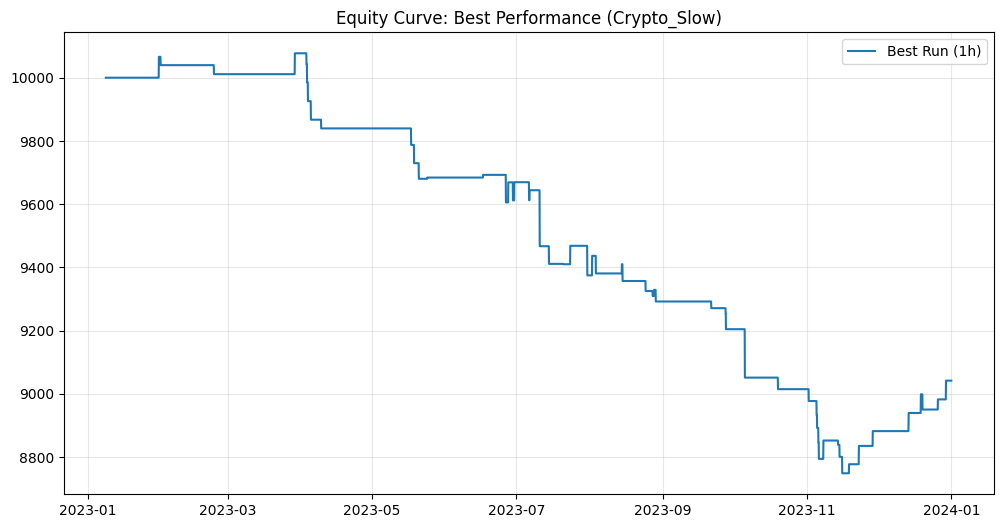

In [2]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CÁC BỘ THAM SỐ (PARAMETER SETS)
# ==============================================================================
# Chúng ta sẽ test 3 bộ tham số Ichimoku phổ biến nhất
ICHIMOKU_PARAMS = {
    'Standard':     {'tenkan': 9,  'kijun': 26, 'span_b': 52, 'displace': 26},
    'Crypto_Fast':  {'tenkan': 10, 'kijun': 30, 'span_b': 60, 'displace': 30}, # Thường dùng cho Crypto 24/7
    'Crypto_Slow':  {'tenkan': 20, 'kijun': 60, 'span_b': 120,'displace': 60}  # Lọc nhiễu tốt hơn
}

TIMEFRAMES_TO_TEST = ['5m', '15m', '1h'] # Test 3 khung này (M1 quá nặng và nhiễu cho demo)

GLOBAL_CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'START_DATE': '01/01/2023',
    'END_DATE': '31/12/2023', # Test 1 năm để chạy nhanh
    'INITIAL_CAPITAL': 10000.0,

    # RSI
    'RSI_PERIOD': 14,
    'RSI_BUY': 55,
    'RSI_SELL': 45,

    # OBI Proxy
    'OBI_VOL_FACTOR': 1.5,
    'OBI_BODY_FACTOR': 0.6,

    # Risk Management
    'SL_PIPS_BUFFER': 10.0, # Scaled later based on TF
    'MAX_RISK_PCT': 0.005,  # 0.5% Risk per trade
    'RR_RATIO': 1.5,
    'TIME_EXIT_CANDLES': 5,

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0001
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval})...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# ==============================================================================
# BƯỚC 4: CORE BACKTEST ENGINE (Đã cập nhật để nhận tham số động)
# ==============================================================================
def run_strategy(df, ichi_params, interval):
    df = df.copy()
    c = GLOBAL_CONFIG

    # --- A. INDICATORS ---
    # 1. Ichimoku (Dynamic Params)
    tenkan_p = ichi_params['tenkan']
    kijun_p = ichi_params['kijun']
    span_b_p = ichi_params['span_b']
    displace = ichi_params['displace']

    high_tenkan = df['High'].rolling(tenkan_p).max()
    low_tenkan = df['Low'].rolling(tenkan_p).min()
    tenkan = (high_tenkan + low_tenkan) / 2

    high_kijun = df['High'].rolling(kijun_p).max()
    low_kijun = df['Low'].rolling(kijun_p).min()
    kijun = (high_kijun + low_kijun) / 2

    df['SpanA'] = ((tenkan + kijun) / 2).shift(displace)

    high_span_b = df['High'].rolling(span_b_p).max()
    low_span_b = df['Low'].rolling(span_b_p).min()
    df['SpanB'] = ((high_span_b + low_span_b) / 2).shift(displace)

    df['Kumo_Top'] = df[['SpanA', 'SpanB']].max(axis=1)
    df['Kumo_Bottom'] = df[['SpanA', 'SpanB']].min(axis=1)

    # 2. RSI
    df['RSI'] = ta.rsi(df['Close'], length=c['RSI_PERIOD'])

    # 3. OBI PROXY
    df['Vol_MA'] = ta.sma(df['Volume'], length=20)
    candle_range = df['High'] - df['Low']
    body_size = (df['Close'] - df['Open']).abs()
    vol_spike = df['Volume'] > (df['Vol_MA'] * c['OBI_VOL_FACTOR'])
    strong_body = body_size > (candle_range * c['OBI_BODY_FACTOR'])

    df['OBI_Buy'] = (df['Close'] > df['Open']) & vol_spike & strong_body
    df['OBI_Sell'] = (df['Close'] < df['Open']) & vol_spike & strong_body

    df.dropna(inplace=True)

    # --- B. EXECUTION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index
    kumo_top = df['Kumo_Top'].values; kumo_bottom = df['Kumo_Bottom'].values
    rsi = df['RSI'].values
    obi_buy = df['OBI_Buy'].values; obi_sell = df['OBI_Sell'].values

    for i in range(1, len(df)):
        # 1. EXIT
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]
            bars_held = i - entry_idx

            if position == 1:
                if obi_sell[i]: # Counter OBI
                    exit_signal = True; exit_reason = "Counter OBI"; raw_exit_price = closes[i]
                elif lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif bars_held >= c['TIME_EXIT_CANDLES']:
                    # Exit if stagnant
                    exit_signal = True; exit_reason = "Time Stop"; raw_exit_price = closes[i]

            elif position == -1:
                if obi_buy[i]:
                    exit_signal = True; exit_reason = "Counter OBI"; raw_exit_price = closes[i]
                elif highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif bars_held >= c['TIME_EXIT_CANDLES']:
                     exit_signal = True; exit_reason = "Time Stop"; raw_exit_price = closes[i]

            if exit_signal:
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)
                trades.append({'PnL': capital * net_pnl, 'Equity': capital})
                position = 0

        # 2. ENTRY
        if position == 0:
            # Scaled Pips Buffer (H1 cần buffer lớn hơn M5)
            # Giả định Pips Buffer scale theo % giá để linh hoạt (0.05% giá)
            scaled_buffer = closes[i] * 0.0005

            # BUY
            was_below = highs[i-1] < kumo_top[i-1]
            break_up = closes[i] > kumo_top[i]
            rsi_ok = rsi[i] >= c['RSI_BUY']
            obi_ok = obi_buy[i]

            if was_below and break_up and rsi_ok and obi_ok:
                position = 1
                entry_idx = i
                entry_price = closes[i] * (1 + c['SLIPPAGE'])

                sl_kumo = kumo_top[i] - scaled_buffer
                sl_pct = entry_price * (1 - c['MAX_RISK_PCT'])
                sl_price = max(sl_kumo, sl_pct)

                risk = entry_price - sl_price
                tp_price = entry_price + (risk * c['RR_RATIO'])

            # SELL
            was_above = lows[i-1] > kumo_bottom[i-1]
            break_down = closes[i] < kumo_bottom[i]
            rsi_ok_sell = rsi[i] <= c['RSI_SELL']
            obi_ok_sell = obi_sell[i]

            if was_above and break_down and rsi_ok_sell and obi_ok_sell:
                position = -1
                entry_idx = i
                entry_price = closes[i] * (1 - c['SLIPPAGE'])

                sl_kumo = kumo_bottom[i] + scaled_buffer
                sl_pct = entry_price * (1 + c['MAX_RISK_PCT'])
                sl_price = min(sl_kumo, sl_pct)

                risk = sl_price - entry_price
                tp_price = entry_price - (risk * c['RR_RATIO'])

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: HÀM TÍNH SHARPE & TỔNG HỢP (GRID SEARCH)
# ==============================================================================
def calculate_sharpe_ratio(equity_curve, timeframe):
    # Xác định số phiên mỗi năm dựa trên timeframe
    periods_per_year = {
        '1m': 365*24*60,
        '5m': 365*24*12,
        '15m': 365*24*4,
        '1h': 365*24,
        '4h': 365*6
    }
    factor = periods_per_year.get(timeframe, 365*24)

    returns = equity_curve.pct_change().dropna()
    if returns.std() == 0: return 0
    return (returns.mean() / returns.std()) * np.sqrt(factor)

def run_optimization():
    results = []

    print(f"🚀 BẮT ĐẦU QUÉT CHIẾN LƯỢC TRÊN {len(TIMEFRAMES_TO_TEST)} KHUNG THỜI GIAN...")

    for tf in TIMEFRAMES_TO_TEST:
        # Tải dữ liệu 1 lần cho mỗi timeframe
        df = fetch_binance_kline_df(GLOBAL_CONFIG['SYMBOL'], tf, GLOBAL_CONFIG['START_DATE'], GLOBAL_CONFIG['END_DATE'])

        if df.empty: continue

        for name, params in ICHIMOKU_PARAMS.items():
            print(f"   Testing: {tf} - Params: {name}...")

            equity, trades_df = run_strategy(df, params, tf)

            if not trades_df.empty:
                final_eq = equity.iloc[-1]
                profit_pct = (final_eq - GLOBAL_CONFIG['INITIAL_CAPITAL']) / GLOBAL_CONFIG['INITIAL_CAPITAL'] * 100
                dd = (equity - equity.cummax()) / equity.cummax()
                max_dd = dd.min() * 100
                sharpe = calculate_sharpe_ratio(equity, tf)

                results.append({
                    'Timeframe': tf,
                    'Param_Set': name,
                    'Return %': round(profit_pct, 2),
                    'Max DD %': round(max_dd, 2),
                    'Sharpe': round(sharpe, 2),
                    'Trades': len(trades_df)
                })
            else:
                results.append({
                    'Timeframe': tf, 'Param_Set': name, 'Return %': 0, 'Max DD %': 0, 'Sharpe': 0, 'Trades': 0
                })

    return pd.DataFrame(results)

# ==============================================================================
# BƯỚC 6: CHẠY VÀ HIỂN THỊ
# ==============================================================================
if __name__ == "__main__":
    result_table = run_optimization()

    if not result_table.empty:
        # Sắp xếp theo Sharpe Ratio từ cao xuống thấp
        result_table = result_table.sort_values(by='Sharpe', ascending=False)

        print("\n" + "="*60)
        print("🏆 BẢNG XẾP HẠNG HIỆU SUẤT CHIẾN LƯỢC")
        print("="*60)
        print(result_table.to_string(index=False))

        # Vẽ biểu đồ của bộ tham số tốt nhất
        best_run = result_table.iloc[0]
        print(f"\n🌟 Best Setting: {best_run['Timeframe']} - {best_run['Param_Set']}")

        # Chạy lại bộ tốt nhất để vẽ hình
        df_best = fetch_binance_kline_df(GLOBAL_CONFIG['SYMBOL'], best_run['Timeframe'], GLOBAL_CONFIG['START_DATE'], GLOBAL_CONFIG['END_DATE'])
        equity_best, _ = run_strategy(df_best, ICHIMOKU_PARAMS[best_run['Param_Set']], best_run['Timeframe'])

        plt.figure(figsize=(12, 6))
        plt.plot(equity_best, label=f"Best Run ({best_run['Timeframe']})")
        plt.title(f"Equity Curve: Best Performance ({best_run['Param_Set']})")
        plt.legend(); plt.grid(True, alpha=0.3)
        plt.show()
    else:
        print("❌ Không có kết quả nào.")